In [46]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from PIL import Image
from keras import models, layers, regularizers, callbacks

In [47]:
SEED = 42
keras.utils.set_random_seed(SEED)

In [48]:
#!unzip /content/drive/MyDrive/GA/archive.zip -d /content/drive/MyDrive/GA/

In [49]:
folder = "/content/drive/MyDrive/UTKFace"

images = [f for f in os.listdir(folder) if f.endswith(".jpg")]
ages = [int(f.split("_")[0]) for f in images]

print("Total images:", len(images))

# Check the number of images for each age
pd.Series(ages).value_counts().sort_index()

Total images: 13581


,count
1,612
2,277
3,155
4,166
5,117
...,...
101,1
105,4
110,2
115,1


In [50]:
len(ages)

13581

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    images, ages, test_size=0.2, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_test, y_test, test_size=0.5, random_state=42
)

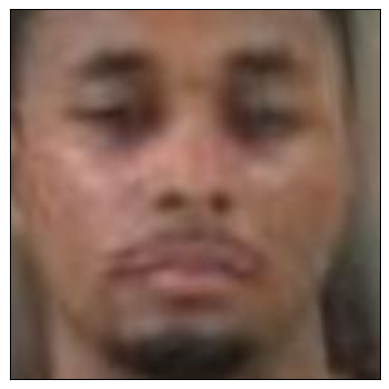

Age: 31


In [52]:
img = Image.open(os.path.join(folder, X_train[0]))

plt.imshow(img)
plt.xticks([])
plt.yticks([])
plt.show()

print("Age:", y_train[0])

In [53]:
def make_dataset(images, ages, batch_size=32):
    paths = [os.path.join(folder, img) for img in images]

    dataset = tf.data.Dataset.from_tensor_slices((paths, ages))

    def load_image(path, age):
        img = tf.io.read_file(path)
        img = tf.io.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, (120, 120))
        return img, tf.cast(age, tf.float32)

    dataset = dataset.map(load_image)
    dataset = dataset.batch(batch_size).prefetch(1)

    return dataset

train_data = make_dataset(X_train, y_train)
val_data = make_dataset(X_val, y_val)
test_data = make_dataset(X_test, y_test)

In [54]:
import keras
from keras import models, layers, regularizers

network = models.Sequential()
network.add(layers.Input(shape=(120,120,3)))

# augmentation
network.add(layers.RandomFlip("horizontal"))
network.add(layers.RandomRotation(0.05))
network.add(layers.RandomZoom(0.05))

network.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
network.add(layers.MaxPooling2D())

network.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
network.add(layers.MaxPooling2D())

network.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
network.add(layers.MaxPooling2D())

network.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
network.add(layers.MaxPooling2D())

network.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
network.add(layers.MaxPooling2D())

network.add(layers.GlobalAveragePooling2D())

# Dense layers
network.add(layers.Dense(128, activation='relu',
                         kernel_regularizer=regularizers.l2(0.001)))

network.add(layers.Dropout(0.3))

# Predict age
network.add(layers.Dense(1))

network.compile(
    optimizer='adam',
    loss='mae',
    metrics=['mae']
)

network.summary()


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_8 (RandomFlip)      │ (None, 120, 120, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_10              │ (None, 120, 120, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_10 (RandomZoom)     │ (None, 120, 120, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_47 (Conv2D)              │ (None, 120, 120, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_44 (MaxPooling2D) │ (None, 60, 60, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_48 (Conv2D)              │ (None, 60, 60, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_45 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_49 (Conv2D)              │ (None, 30, 30, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_46 (MaxPooling2D) │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_50 (Conv2D)              │ (None, 15, 15, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_47 (MaxPooling2D) │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_51 (Conv2D)              │ (None, 7, 7, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_48 (MaxPooling2D) │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 294,401 (1.12 MB)

 Trainable params: 294,401 (1.12 MB)

 Non-trainable params: 0 (0.00 B)

In [55]:
callbacks_phase = [
    callbacks.ModelCheckpoint(
        filepath="age_model.keras",
        save_best_only=True,
        monitor="val_loss",
        verbose=1
    ),

    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),
]

In [62]:
network.compile(
    optimizer='adam',
    loss='mae',
    metrics=['mae']
)

history = network.fit(
    train_data,
    validation_data=val_data,
    epochs=80,
    callbacks=callbacks_phase
)

Epoch 1/80
327/340 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.7580 - mae: 7.7325
Epoch 1: val_loss did not improve from 7.45339
340/340 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 7.7690 - mae: 7.7440 - val_loss: 7.8132 - val_mae: 7.7884
Epoch 2/80
338/340 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.7780 - mae: 7.7532
Epoch 2: val_loss did not improve from 7.45339
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 7.8762 - mae: 7.8516 - val_loss: 7.4718 - val_mae: 7.4475
Epoch 3/80
327/340 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.7886 - mae: 7.7643
Epoch 3: val_loss did not improve from 7.45339
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 7.7792 - mae: 7.7549 - val_loss: 7.5110 - val_mae: 7.4868
Epoch 4/80
326/340 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.5961 - mae: 7.5718
Epoch 4: val_loss did not improve from 7.45339
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 7.6462 - mae: 7.6219 - val_loss: 7.6727 - val_mae: 7.6482
Epoch 5/80
334/340 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 

In [63]:
network.evaluate(test_data)

43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.8389 - mae: 6.8171


[6.838929176330566, 6.817112445831299]

In [64]:
history_df = pd.DataFrame(history.history)
history_df.head()

,loss,mae,val_loss,val_mae
0,7.768965,7.744002,7.813194,7.788351
1,7.876233,7.851620,7.471783,7.447514
2,7.779214,7.754917,7.511027,7.486773
3,7.646221,7.621863,7.672681,7.648154
4,7.557600,7.533316,7.366140,7.341784


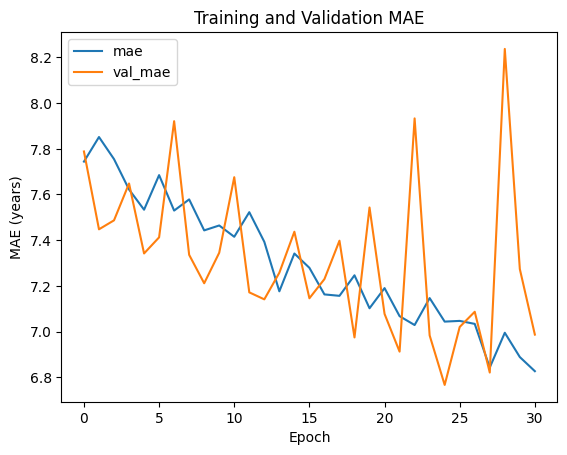

In [65]:
history_df[['mae', 'val_mae']].plot()
plt.title('Training and Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE (years)')
plt.show()

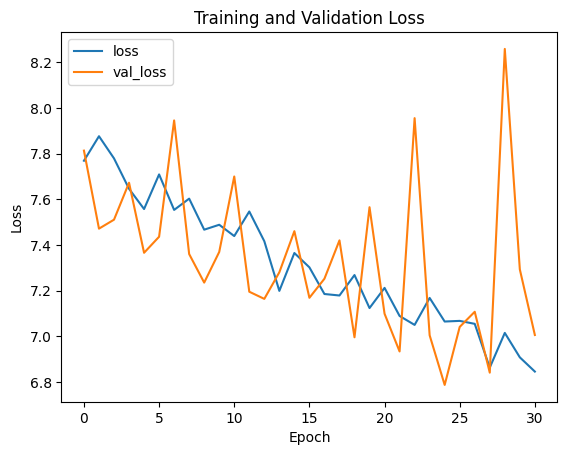

In [66]:
history_df[['loss', 'val_loss']].plot()
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()


In [67]:
# Save the best weights restored by EarlyStopping
network.save("age_model.keras")